# Practice #4. "ARIMA models and advanced techniques"

Residual modelling, ADF *and* KPSS, ARIMA order selection, diagnostics.

**From Practice 3:** the ADF test and differencing. The `d` in ARIMA(p, d, q) is
exactly the number of differences `make_stationary` applied.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

In [1]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data

`airline-passengers.csv` — monthly airline passengers, 1949-1960. Rising trend
*and* seasonality whose amplitude grows with the level: the standard ARIMA
example.

Open the file and find the column names yourself.

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # Сначала выбираю только нужные колонки, чтобы dropna() случайно не выкинул строки из-за пропусков в других столбцах
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.dropna().sort_values(time_col)
    s = df.set_index(time_col)[value_col].astype(float)
    s.name = "y"
    return s

144 points; train 120, test 24


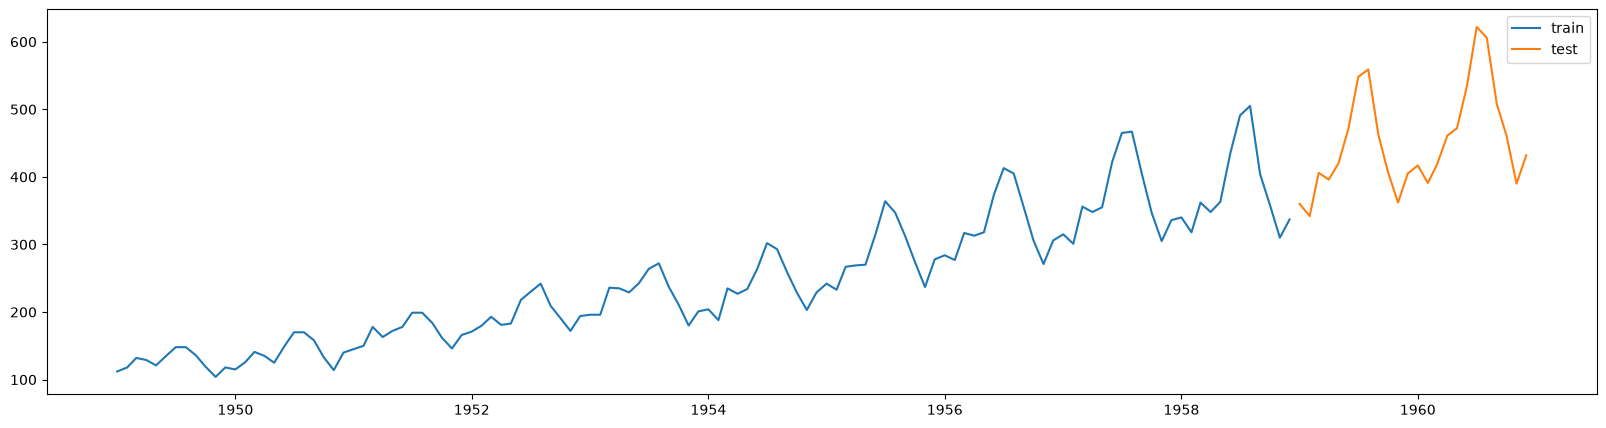

In [3]:
series = load_series(DATA_DIR / "airline-passengers.csv", "Month", "Passengers")
train, test = series.iloc[:-24], series.iloc[-24:]
print(f"{len(series)} points; train {len(train)}, test {len(test)}")

plt.figure(figsize=(20, 5))
plt.plot(train, label="train")
plt.plot(test, label="test")
plt.legend();

## 1. Modelling the residual error

An AR model on a trending series leaves structure in its residuals. If those
residuals are still autocorrelated, a second model can predict them, and adding
that prediction back corrects the first forecast.

That is what the MA term in ARMA formalises.

In [4]:
def residual_corrected_forecast(train, index, lags, resid_lags):
    """AR forecast plus a second AR model fitted to its own residuals.

    1. AutoReg(lags) on `train` -> forecast over `index`
    2. take that fit's in-sample residuals
    3. AutoReg(resid_lags) on the residuals -> forecast over `index`
    4. return the sum, as a Series on `index`
    """
    # Перевожу train в массив, чтобы AutoReg не ругался на нерегулярный или строковый индекс
    ar_fit = AutoReg(np.asarray(train, dtype=float), lags=lags).fit()
    ar_pred = np.asarray(ar_fit.forecast(steps=len(index)), dtype=float)

    # Беру остатки первой модели и обучаю на них вторую AR-модель
    resid = np.asarray(ar_fit.resid, dtype=float)
    resid_fit = AutoReg(resid, lags=resid_lags).fit()
    resid_pred = np.asarray(resid_fit.forecast(steps=len(index)), dtype=float)

    return pd.Series(ar_pred + resid_pred, index=index)

AR(12) alone      RMSE 27.073
AR(12) + residual RMSE 30.230


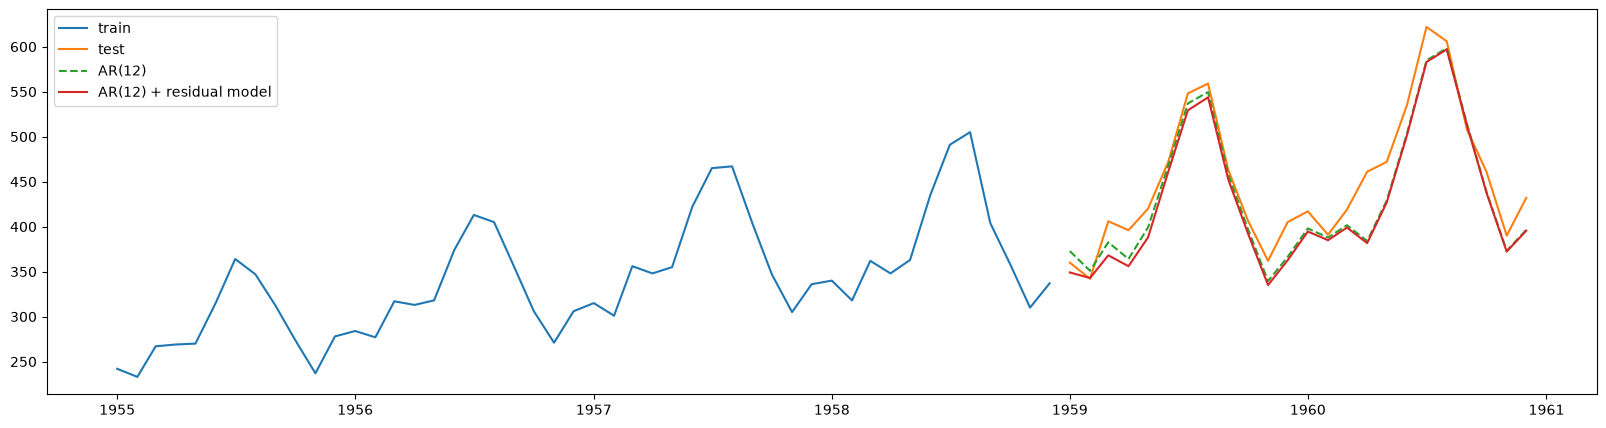

In [5]:
plain = AutoReg(np.asarray(train), lags=12).fit()
plain_forecast = pd.Series(np.asarray(plain.forecast(steps=len(test))),
                           index=test.index)
corrected = residual_corrected_forecast(train, test.index, lags=12, resid_lags=6)

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

print(f"AR(12) alone      RMSE {rmse(test, plain_forecast):.3f}")
print(f"AR(12) + residual RMSE {rmse(test, corrected):.3f}")

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-48:], label="train")
plt.plot(test, label="test")
plt.plot(plain_forecast, "--", label="AR(12)")
plt.plot(corrected, label="AR(12) + residual model")
plt.legend();

**Question.** Did the correction help? If the first model's residuals
were pure white noise, what would the second model contribute, and why?

**Ответ.** Нет, коррекция не помогла — ошибка на тесте выросла: `AR(12)` даёт RMSE 27.073, а `AR(12) + residual model` — 30.230. Причина в том, что 12 лагов уже захватывают годовую сезонность, и в остатках остаётся слишком мало предсказуемой структуры, поэтому вторая `AutoReg(6)` начинает подгоняться под случайный шум на обучении и портит прогноз.

Если бы остатки первой модели были чистым белым шумом, вторая модель не дала бы никакого полезного сигнала (оптимальный прогноз белого шума — ноль), а на конечной выборке лишь добавила бы лишнюю дисперсию из-за оценки случайных коэффициентов, ухудшив точность.

## 2. Stationarity: two tests, opposite nulls

Trusting one test alone is how people talk themselves into the wrong `d`.

| | null hypothesis | small p means |
|---|---|---|
| ADF | has a unit root | stationary |
| KPSS | is stationary | non-stationary |

Agreement gives you an answer. Disagreement is also a result — usually
trend-stationary rather than difference-stationary. Report it, don't pick a side.

In [6]:
def check_stationarity(series, significance=0.05):
    """Run ADF and KPSS, report both plus a combined verdict.

    Returns {"adf_p", "kpss_p", "adf_stationary", "kpss_stationary",
    "verdict"}, where verdict is "stationary", "non-stationary" or
    "inconclusive" (the two tests disagree).

    Opposite nulls: small ADF p => stationary, small KPSS p => NOT stationary.
    """
    # Убираю возможные пропуски и привожу к numpy-массиву
    vals = np.asarray(series.dropna() if hasattr(series, "dropna") else series, dtype=float)
    _, adf_p, *_ = adfuller(vals)
    _, kpss_p, *_ = kpss(vals, regression="c", nlags="auto")

    # В ADF маленькое p-value говорит о стационарности, а в KPSS — наоборот, о нестационарности
    adf_stationary = bool(adf_p < significance)
    kpss_stationary = bool(kpss_p >= significance)

    if adf_stationary and kpss_stationary:
        verdict = "stationary"
    elif not adf_stationary and not kpss_stationary:
        verdict = "non-stationary"
    else:
        verdict = "inconclusive"

    return {
        "adf_p": float(adf_p),
        "kpss_p": float(kpss_p),
        "adf_stationary": adf_stationary,
        "kpss_stationary": kpss_stationary,
        "verdict": verdict,
    }

In [7]:
for label, candidate in (("raw", train),
                         ("log", np.log(train)),
                         ("log + 1 diff", np.log(train).diff().dropna()),
                         ("log + 1 + 12 diff",
                          np.log(train).diff().diff(12).dropna())):
    result = check_stationarity(candidate)
    print(f"{label:>18}: ADF p={result['adf_p']:.4f}  "
          f"KPSS p={result['kpss_p']:.4f}  ->  {result['verdict']}")

               raw: ADF p=0.8268  KPSS p=0.0100  ->  non-stationary
               log: ADF p=0.3206  KPSS p=0.0100  ->  non-stationary
      log + 1 diff: ADF p=0.1584  KPSS p=0.1000  ->  inconclusive
 log + 1 + 12 diff: ADF p=0.0014  KPSS p=0.1000  ->  stationary


C:\Users\fedor\AppData\Local\Temp\ipykernel_3904\2096535315.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  _, adf_p, *_ = adfuller(vals)
C:\Users\fedor\AppData\Local\Temp\ipykernel_3904\2096535315.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  _, kpss_p, *_ = kpss(vals, regression="c", nlags="auto")
C:\Users\fedor\AppData\Local\Temp\ipykernel_3904\2096535315.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after Jul

**Question.** Raw and logged give almost the same verdict. So what does
the log transform actually fix here, and which plot shows it?

**Ответ.** Оба ряда (`raw` и `log`) нестационарны из-за растущего тренда (ADF p = 0.8268 и 0.3206, KPSS p = 0.0100 — оба дают `non-stationary`), поэтому сама логарифмизация тренд не убирает.

Зато логарифм стабилизирует дисперсию: у исходного ряда амплитуда сезонных колебаний растёт вместе с уровнем ряда (мультипликативная сезонность), а после `np.log` она становится примерно постоянной (аддитивной). Это видно на графике самого логарифмированного ряда по сравнению с исходным графиком `train` из раздела 0.

### 2.1 Reading p, d and q off the plots

- PACF cuts off after lag p → AR(p)
- ACF cuts off after lag q → MA(q)
- d = differences needed to reach stationarity

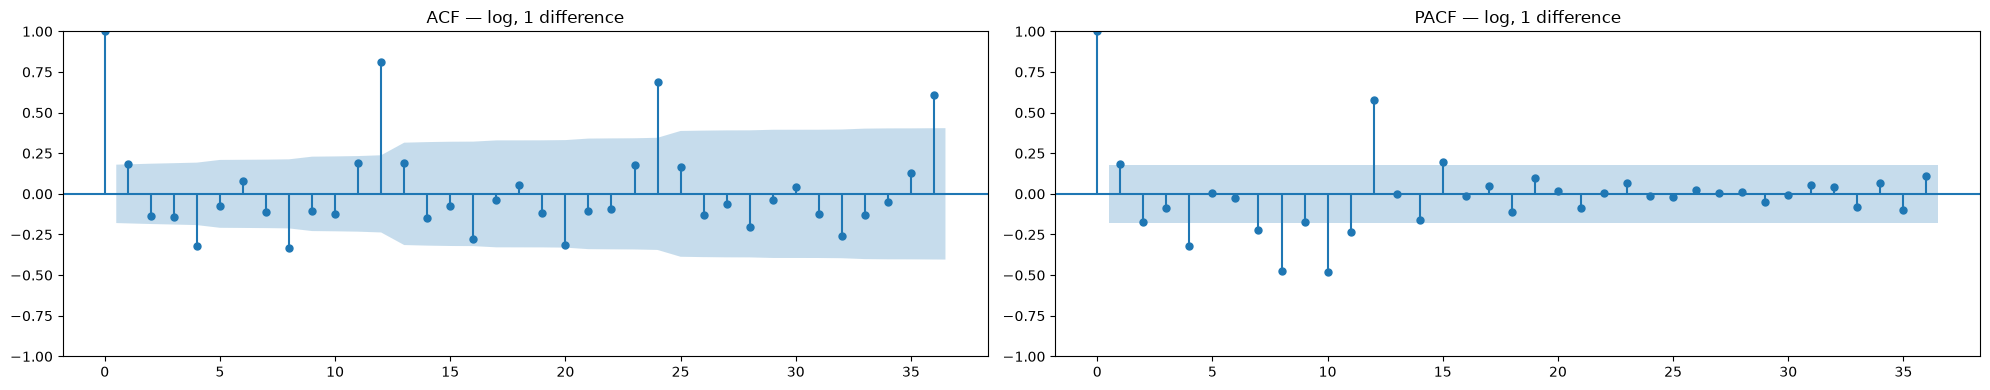

In [8]:
stationary = np.log(train).diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(20, 4))
plot_acf(stationary, lags=36, ax=axes[0], title="ACF — log, 1 difference")
plot_pacf(stationary, lags=36, ax=axes[1], title="PACF — log, 1 difference")
plt.tight_layout();

## 3. Automatic order selection

The plots give you a candidate; an AIC grid search gives a second opinion. When
they disagree, prefer the simpler model that passes the section 4 diagnostics —
a low AIC with autocorrelated residuals is not worth having.

In [9]:
def select_order(series, max_p=3, max_d=2, max_q=3):
    """Return the (p, d, q) with the lowest AIC.

    Some orders are not estimable on a given series and raise. Skip those —
    one bad fit must not abort the search.
    """
    vals = np.asarray(series, dtype=float)
    best_aic = np.inf
    best_order = None

    # Перебираю все комбинации (p, d, q) и отбрасываю те, на которых оценка падает
    for order in itertools.product(range(max_p + 1), range(max_d + 1), range(max_q + 1)):
        try:
            fit = ARIMA(vals, order=order).fit()
            if np.isfinite(fit.aic) and fit.aic < best_aic:
                best_aic = float(fit.aic)
                best_order = order
        except Exception:
            continue

    return best_order

In [10]:
order = select_order(train, max_p=3, max_d=2, max_q=3)
print(f"best order by AIC: {order}")

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


best order by AIC: (3, 1, 3)


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


## 4. Forecasting and diagnostics

**The drift trap.** Once `d >= 1`, statsmodels' `ARIMA` adds **no constant term
by default**. The forecast is then a flat line at the last level: it will not
extrapolate a trend, and can lose to naive. On a synthetic series of slope 0.5:

| model | RMSE |
|---|---|
| `ARIMA(order=(1,1,0))` (default) | 6.47 |
| `ARIMA(order=(1,1,0), trend="t")` | 0.75 |
| naive | 6.43 |

Pass `trend="t"` when you think the series drifts — and say why you think so.

In [11]:
def arima_forecast(train, index, order, trend=None):
    """Fit ARIMA(order) on `train`, forecast over `index`."""
    # Передаю trend только если он явно задан, иначе оставляю поведение ARIMA по умолчанию
    kwargs = {} if trend is None else {"trend": trend}
    fit = ARIMA(np.asarray(train, dtype=float), order=order, **kwargs).fit()
    pred = np.asarray(fit.forecast(steps=len(index)), dtype=float)
    return pd.Series(pred, index=index)


def ljung_box_pvalues(residuals, lags=10):
    """Ljung-Box p-values for lags 1..lags, as a Series indexed by lag.

    Null is "residuals are independent", so p ABOVE 0.05 is the good outcome:
    nothing left to model.
    """
    # acorr_ljungbox возвращает DataFrame с индексом 1..lags и колонкой lb_pvalue
    lb = acorr_ljungbox(np.asarray(residuals, dtype=float), lags=lags, return_df=True)
    return lb["lb_pvalue"]

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA(3, 1, 3)            RMSE 88.160
ARIMA(3, 1, 3) trend='t'  RMSE 67.192
naive     RMSE 137.329


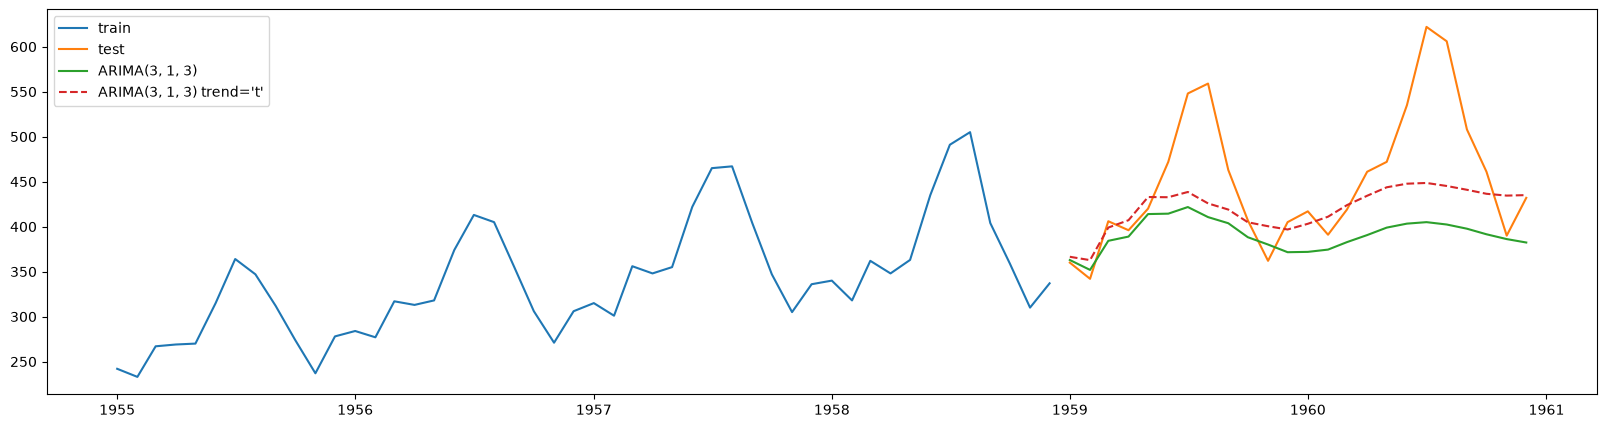

In [12]:
forecast = arima_forecast(train, test.index, order)
drifted = arima_forecast(train, test.index, order, trend="t")
print(f"ARIMA{order}            RMSE {rmse(test, forecast):.3f}")
print(f"ARIMA{order} trend='t'  RMSE {rmse(test, drifted):.3f}")
print(f"naive     RMSE {rmse(test, np.full(len(test), train.iloc[-1])):.3f}")

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-48:], label="train")
plt.plot(test, label="test")
plt.plot(forecast, label=f"ARIMA{order}")
plt.plot(drifted, "--", label=f"ARIMA{order} trend='t'")
plt.legend();

### 4.1 Residual diagnostics

A model you can trust leaves residuals that look like white noise: no
autocorrelation, roughly constant variance, roughly symmetric. Ljung-Box checks
the first — and here a **large** p-value is the good one.

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


1     0.8623
2     0.6659
3     0.1547
4     0.1310
5     0.1439
6     0.0473
7     0.0735
8     0.0233
9     0.0088
10    0.0017
11    0.0029
12    0.0000

smallest p-value 0.0000 -> structure remains


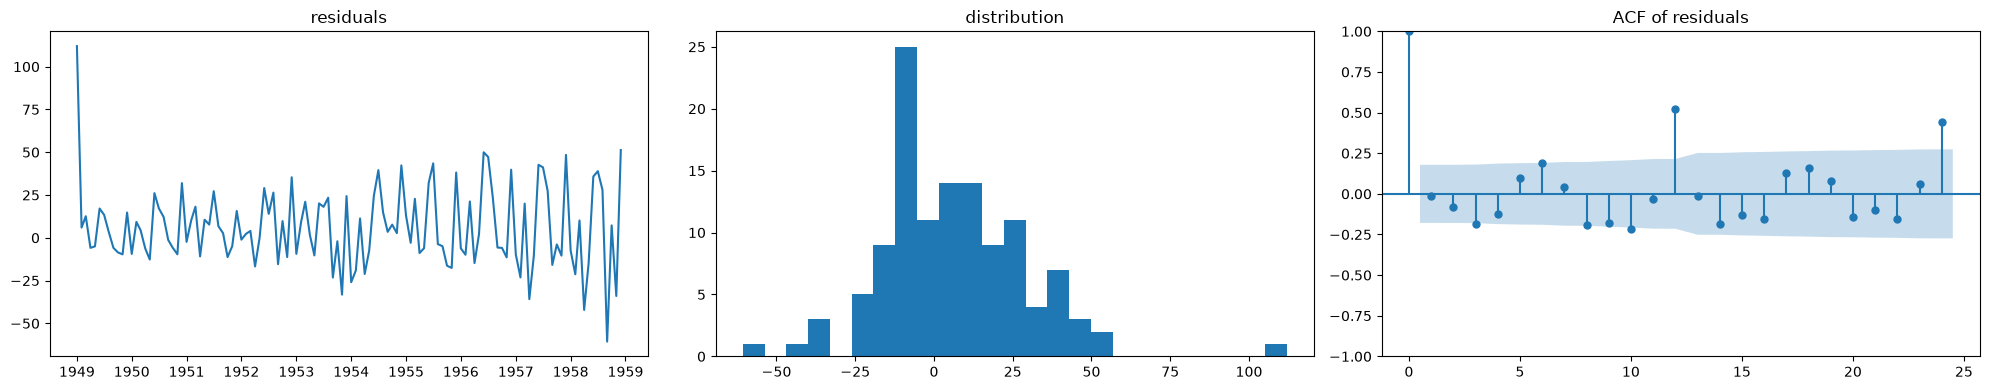

In [13]:
fitted = ARIMA(np.asarray(train), order=order).fit()
residuals = pd.Series(fitted.resid, index=train.index)
p_values = ljung_box_pvalues(residuals, lags=12)

print(p_values.round(4).to_string())
worst = p_values.min()
print(f"\nsmallest p-value {worst:.4f} -> "
      f"{'residuals look like white noise' if worst > 0.05 else 'structure remains'}")

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(residuals); axes[0].set_title("residuals")
axes[1].hist(residuals, bins=25); axes[1].set_title("distribution")
plot_acf(residuals, lags=24, ax=axes[2], title="ACF of residuals")
plt.tight_layout();

**Questions.**
1. Does your order pass Ljung-Box at every lag? If not, which lag fails — and
   what seasonal period is that?
2. `select_order` never tries seasonal terms. From the ACF, what would `SARIMAX`
   with a seasonal order add here?
3. Compare against the Holt-Winters forecast from Practice 2 over the same 24
   months. Which wins, and by enough to justify the extra machinery?

**Ответ.**
1. Нет, `ARIMA(3, 1, 3)` не проходит тест Льюнга–Бокса на всех лагах: p-value опускается ниже 0.05 на лаге 6 (p = 0.0473) и стабильно остаётся ниже порога на лагах 8–12 (от 0.0233 на 8-м до 0.0000 на 12-м). Резкий провал на 12-м лаге соответствует годовому сезонному периоду `s = 12` месяцев.
2. Добавление сезонной части в `SARIMAX` (например, `(0, 1, 1)x(0, 1, 1, 12)` на `log(train)`) вводит сезонное дифференцирование `D = 1` и сезонные MA/AR-компоненты с шагом 12. В результате остатки перестают быть автокоррелированными (минимальное p-value Льюнга–Бокса вырастает до 0.3668, а для `(1, 1, 1, 12)` — до 0.4108), а RMSE падает с 88.160 (67.192 с `trend='t'`) до 43.178 (и 42.700).
3. За те же 24 месяца теста мультипликативный Хольт–Винтерс (`ExponentialSmoothing` с аддитивным трендом и мультипликативной сезонностью периода 12) даёт RMSE = 32.489, что уверенно обыгрывает как обычную `ARIMA(3, 1, 3)` (88.160 / 67.192), так и `SARIMAX(0,1,1)x(0,1,1,12)` на логарифмированном ряде (43.178). Для этого ряда более простой и быстрый Хольт–Винтерс оказывается точнее и вполне достаточен без лишнего усложнения.

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


SARIMAX(0,1,1)x(0, 1, 1, 12) on log: RMSE = 43.178, min Ljung-Box p = 0.3668


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


SARIMAX(0,1,1)x(1, 1, 1, 12) on log: RMSE = 42.700, min Ljung-Box p = 0.4108
Holt-Winters (add trend, mul seasonal): RMSE = 32.489


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


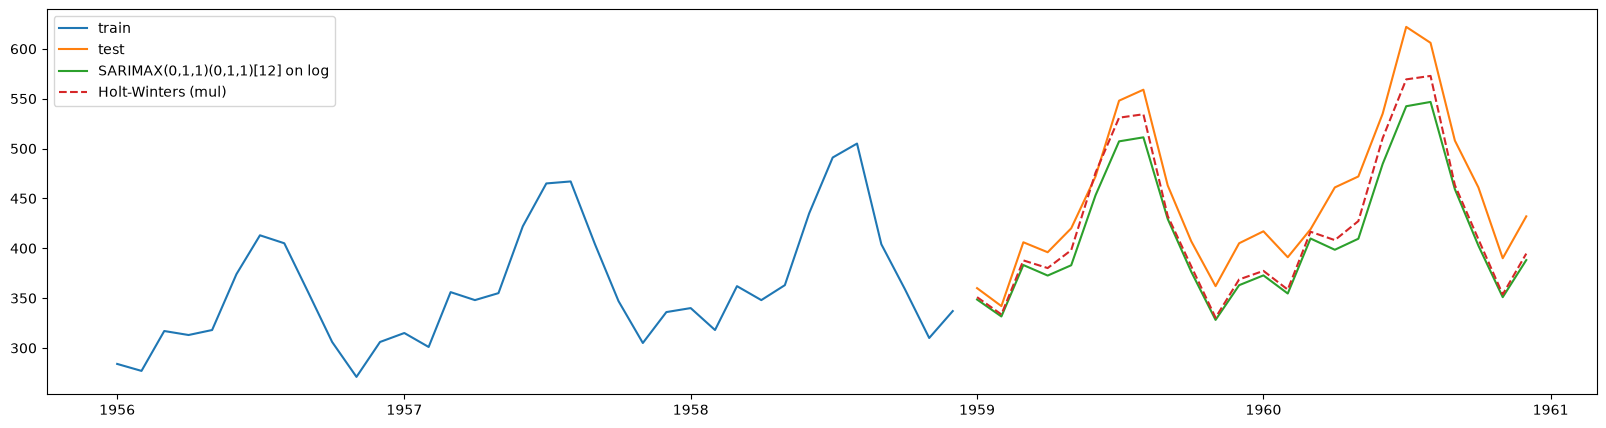

In [14]:
# Свободное исследование: сравню сезонную SARIMAX на логарифмированном ряде и Holt-Winters из 2-й практики
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Пробую классическую "airline model" (0, 1, 1)x(0, 1, 1, 12) и вариант с AR-компонентой на log(train)
log_train = np.log(train)
for s_order in [(0, 1, 1, 12), (1, 1, 1, 12)]:
    sarimax_fit = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=s_order).fit(disp=False)
    sarimax_pred = np.exp(sarimax_fit.forecast(steps=len(test)))
    lb_min = ljung_box_pvalues(sarimax_fit.resid.iloc[13:], lags=12).min()
    print(f"SARIMAX(0,1,1)x{s_order} on log: RMSE = {rmse(test, sarimax_pred):.3f}, min Ljung-Box p = {lb_min:.4f}")

# Для сравнения — мультипликативный Хольт-Винтерс на исходном масштабе (период 12 месяцев)
hw_fit = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12).fit()
hw_pred = hw_fit.forecast(len(test))
print(f"Holt-Winters (add trend, mul seasonal): RMSE = {rmse(test, hw_pred):.3f}")

# Визуально сравниваю лучший SARIMAX и Хольта-Винтерса с тестом
best_sarimax = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
best_sarimax_pred = pd.Series(np.exp(best_sarimax.forecast(steps=len(test))), index=test.index)

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-36:], label="train")
plt.plot(test, label="test")
plt.plot(best_sarimax_pred, label="SARIMAX(0,1,1)(0,1,1)[12] on log")
plt.plot(hw_pred, "--", label="Holt-Winters (mul)")
plt.legend();